# Personal Expense Tracker

### Python Mini Project

**Purpose:** A simple, beginner-friendly expense tracker that lets a user add expenses, view them, save them to a CSV file, generate spending reports, and visualize spending with charts.

This notebook follows the project requirements: lists/dictionaries for data, functions for each operation, CSV file handling, calculations, error handling, loops/conditions, and Matplotlib visualizations.


## 1. Project Objectives

- Add and categorize personal expenses.
- View all recorded expenses in a readable format.
- Calculate total spending and category-wise spending.
- Save expenses permanently in a CSV file.
- Load previously saved expenses when the notebook is reopened.
- Display simple charts for spending analysis.
- Handle invalid input safely instead of stopping the program unexpectedly.


## 2. Technologies Used

- **Python** – main programming language
- **CSV module** – file storage
- **datetime** – date validation and date handling
- **Matplotlib** – charts and visual analysis
- **Lists and dictionaries** – storing and organizing expenses


In [55]:
import csv
from datetime import datetime
from pathlib import Path
from collections import defaultdict
import matplotlib.pyplot as plt

CSV_FILE = Path("expenses.csv")

# Each expense is stored as a dictionary.
expenses = []

print("Personal Expense Tracker is ready!")

Personal Expense Tracker is ready!


## 3. Data Structure

Each expense is represented as a dictionary with four fields: `date`, `category`, `description`, and `amount`. All dictionaries are stored inside the `expenses` list.

Example:

```text
{
    'date': '2026-10-02',
    'category': 'Food',
    'description': 'Lunch',
    'amount': 120.00
}
```

In [56]:
from datetime import datetime
from collections import defaultdict

# This list stores all the expenses
expenses = []


# Check whether the date is correct
def validate_date(date_text):
    try:
        datetime.strptime(date_text, "%Y-%m-%d")
        return date_text
    except ValueError:
        raise ValueError("Please enter date in YYYY-MM-DD format.")


# Check whether the amount is valid
def validate_amount(amount):
    try:
        amount = float(amount)
    except (ValueError, TypeError):
        raise ValueError("Please enter a valid number.")

    if amount <= 0:
        raise ValueError("Amount should be greater than zero.")

    return round(amount, 2)


# Add a new expense
def add_expense(amount, category, description, date=None):

    # Check category
    if not category or not category.strip():
        raise ValueError("Category cannot be empty.")

    # Check description
    if not description or not description.strip():
        raise ValueError("Description cannot be empty.")

    # If the user does not enter a date,
    # today's date will be used
    if date is None:
        date = datetime.now().strftime("%Y-%m-%d")

    # Validate the date and amount
    date = validate_date(date)
    amount = validate_amount(amount)

    # Create one expense record
    expense = {
        "date": date,
        "category": category.strip().title(),
        "description": description.strip(),
        "amount": amount
    }

    # Add the expense to the list
    expenses.append(expense)

    return expense


# Display all expenses
def view_expenses(data=None):

    # If no data is given, use all expenses
    if data is None:
        data = expenses

    # Check if there are no expenses
    if not data:
        print("No expenses found.")
        return

    # Print table headings
    print(
        f"{'#':<4}"
        f"{'Date':<13}"
        f"{'Category':<18}"
        f"{'Description':<25}"
        f"{'Amount':>10}"
    )

    print("-" * 70)

    # Display each expense
    for number, expense in enumerate(data, start=1):
        print(
            f"{number:<4}"
            f"{expense['date']:<13}"
            f"{expense['category']:<18}"
            f"{expense['description']:<25}"
            f"₹{expense['amount']:>9.2f}"
        )


# Calculate total spending
def total_spending(data=None):

    if data is None:
        data = expenses

    total = 0

    for expense in data:
        total += expense["amount"]

    return round(total, 2)


# Calculate spending for each category
def spending_by_category(data=None):

    if data is None:
        data = expenses

    category_total = defaultdict(float)

    # Add the amount to its category
    for expense in data:
        category = expense["category"]
        category_total[category] += expense["amount"]

    # Round the values and sort the categories
    result = {}

    for category in sorted(category_total):
        result[category] = round(category_total[category], 2)

    return result

## 4. Add Some Sample Expenses

The following sample records make the notebook immediately testable. You can remove this cell and enter your own expenses instead.

In [57]:
expenses.clear()

sample_expenses = [
    (120, "Food", "Lunch", "2026-10-01"),
    (80, "Transport", "Bus", "2026-10-01"),
    (450, "Shopping", "Clothes", "2026-10-02"),
    (250, "Entertainment", "Movie", "2026-10-02"),
    (600, "Education", "Course Fee", "2026-10-02"),
    (150, "Food", "Dinner", "2026-10-03"),
    (100, "Transport", "Cab", "2026-10-03")
]

for amount, category, description, date in sample_expenses:
    add_expense(amount, category, description, date)

view_expenses()
print(f"\nTotal spending: ₹{total_spending():,.2f}")

#   Date         Category          Description                  Amount
----------------------------------------------------------------------
1   2026-10-01   Food              Lunch                    ₹   120.00
2   2026-10-01   Transport         Bus                      ₹    80.00
3   2026-10-02   Shopping          Clothes                  ₹   450.00
4   2026-10-02   Entertainment     Movie                    ₹   250.00
5   2026-10-02   Education         Course Fee               ₹   600.00
6   2026-10-03   Food              Dinner                   ₹   150.00
7   2026-10-03   Transport         Cab                      ₹   100.00

Total spending: ₹1,750.00


## 5. CSV File Handling

The tracker uses a CSV file so that expenses can be kept after the notebook session ends. The same file can also be opened in Excel or Google Sheets.

In [58]:
import csv
from pathlib import Path

# Name of the CSV file
CSV_FILE = "expenses.csv"


# Save all expenses into the CSV file
def save_expenses(filename=CSV_FILE):

    with open(filename, "w", newline="", encoding="utf-8") as file:

        # Create CSV writer
        writer = csv.DictWriter(
            file,
            fieldnames=["date", "category", "description", "amount"]
        )

        # Write column names
        writer.writeheader()

        # Write all expense records
        for expense in expenses:
            writer.writerow(expense)

    print(f"Saved {len(expenses)} expense(s) to {filename}.")


# Load expenses from the CSV file
def load_expenses(filename=CSV_FILE):

    # Check whether the file exists
    if not Path(filename).exists():
        print("No saved expense file found.")
        print("Starting with an empty expense tracker.")
        return []

    loaded_expenses = []

    # Open the CSV file
    with open(filename, "r", newline="", encoding="utf-8") as file:

        reader = csv.DictReader(file)

        # Read each row from the file
        for row in reader:

            try:
                expense = {
                    "date": validate_date(row["date"]),
                    "category": row["category"].strip().title(),
                    "description": row["description"].strip(),
                    "amount": validate_amount(row["amount"])
                }

                loaded_expenses.append(expense)

            except (KeyError, ValueError) as error:
                print(f"Skipped an invalid row: {error}")

    # Replace old expenses with loaded expenses
    expenses.clear()
    expenses.extend(loaded_expenses)

    print(f"Loaded {len(expenses)} expense(s) from {filename}.")

    return expenses


# Save the expenses
save_expenses()

Saved 7 expense(s) to expenses.csv.


In [59]:
# Test loading the saved data.
load_expenses()
view_expenses()

Loaded 7 expense(s) from expenses.csv.
#   Date         Category          Description                  Amount
----------------------------------------------------------------------
1   2026-10-01   Food              Lunch                    ₹   120.00
2   2026-10-01   Transport         Bus                      ₹    80.00
3   2026-10-02   Shopping          Clothes                  ₹   450.00
4   2026-10-02   Entertainment     Movie                    ₹   250.00
5   2026-10-02   Education         Course Fee               ₹   600.00
6   2026-10-03   Food              Dinner                   ₹   150.00
7   2026-10-03   Transport         Cab                      ₹   100.00


## 6. Reports and Calculations

The report gives a quick summary of the recorded spending and identifies the category with the highest total.

In [60]:
def generate_report(data=None):
    """Print a simple expense summary."""
    data = expenses if data is None else data

    if not data:
        print("No expenses available for the report.")
        return

    category_totals = spending_by_category(data)
    highest_category = max(category_totals, key=category_totals.get)
    average = total_spending(data) / len(data)

    print("=" * 45)
    print("PERSONAL EXPENSE REPORT")
    print("=" * 45)
    print(f"Number of expenses : {len(data)}")
    print(f"Total spending    : ₹{total_spending(data):,.2f}")
    print(f"Average expense   : ₹{average:,.2f}")
    print(f"Highest category  : {highest_category} (₹{category_totals[highest_category]:,.2f})")
    print("\nSpending by category:")
    for category, amount in category_totals.items():
        print(f"- {category:<18} ₹{amount:,.2f}")
    print("=" * 45)


generate_report()

PERSONAL EXPENSE REPORT
Number of expenses : 7
Total spending    : ₹1,750.00
Average expense   : ₹250.00
Highest category  : Education (₹600.00)

Spending by category:
- Education          ₹600.00
- Entertainment      ₹250.00
- Food               ₹270.00
- Shopping           ₹450.00
- Transport          ₹180.00


## 7. Highest Expense

In [61]:
def highest_expense(data=None):
    data = expenses if data is None else data

    if not data:
        return None

    return max(data, key=lambda item: item["amount"])

In [62]:
highest = highest_expense()

print("Highest Expense:")
print(f"Amount      : ₹{highest['amount']:,.2f}")
print(f"Category    : {highest['category']}")
print(f"Description : {highest['description']}")
print(f"Date        : {highest['date']}")

Highest Expense:
Amount      : ₹600.00
Category    : Education
Description : Course Fee
Date        : 2026-10-02


## 8. Data Visualization

Charts make it easier to understand where money is being spent. The project includes a bar chart and a pie chart for category-wise spending.

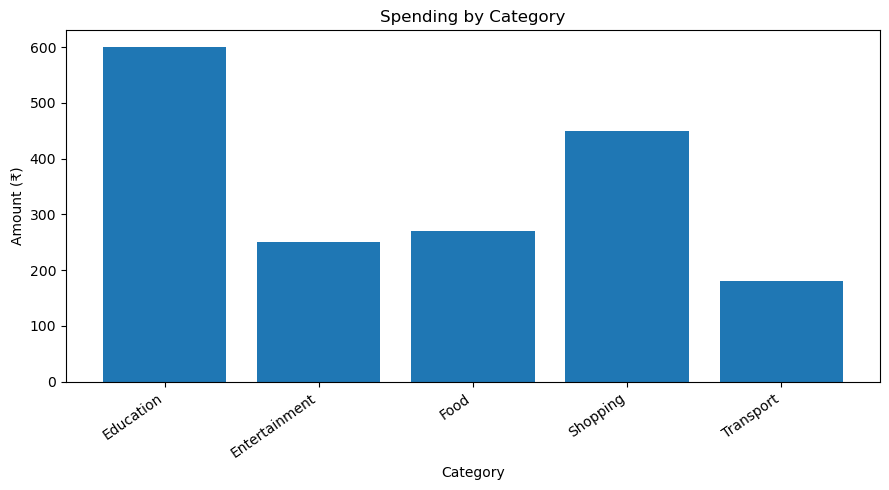

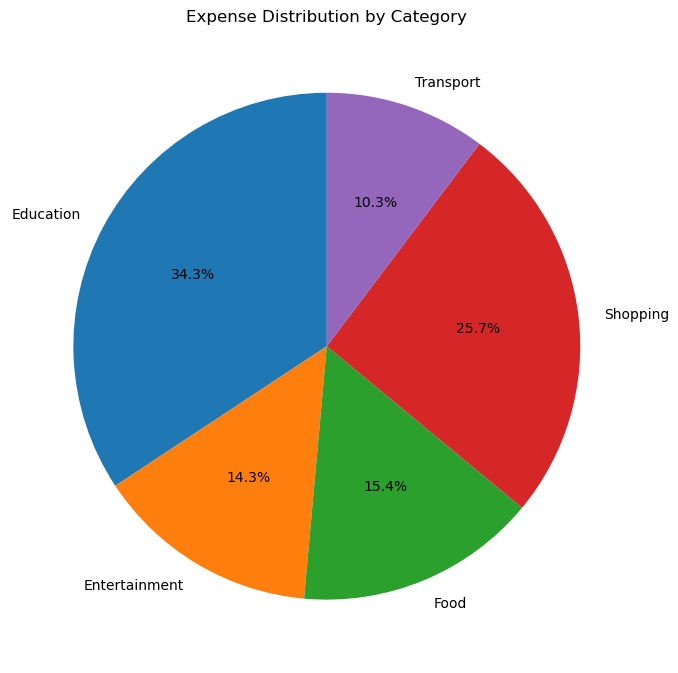

In [63]:
def plot_category_bar(data=None):
    data = expenses if data is None else data
    totals = spending_by_category(data)

    if not totals:
        print("No data available for the chart.")
        return

    plt.figure(figsize=(9, 5))
    plt.bar(totals.keys(), totals.values())
    plt.title("Spending by Category")
    plt.xlabel("Category")
    plt.ylabel("Amount (₹)")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()


def plot_category_pie(data=None):
    data = expenses if data is None else data
    totals = spending_by_category(data)

    if not totals:
        print("No data available for the chart.")
        return

    plt.figure(figsize=(7, 7))
    plt.pie(
        totals.values(),
        labels=totals.keys(),
        autopct="%1.1f%%",
        startangle=90
    )
    plt.title("Expense Distribution by Category")
    plt.tight_layout()
    plt.show()


plot_category_bar()
plot_category_pie()

## 9. Monthly Spending Analysis

This section groups expenses by month. It is useful when the user wants to compare spending over time.

Monthly totals:
2026-10: ₹1,750.00


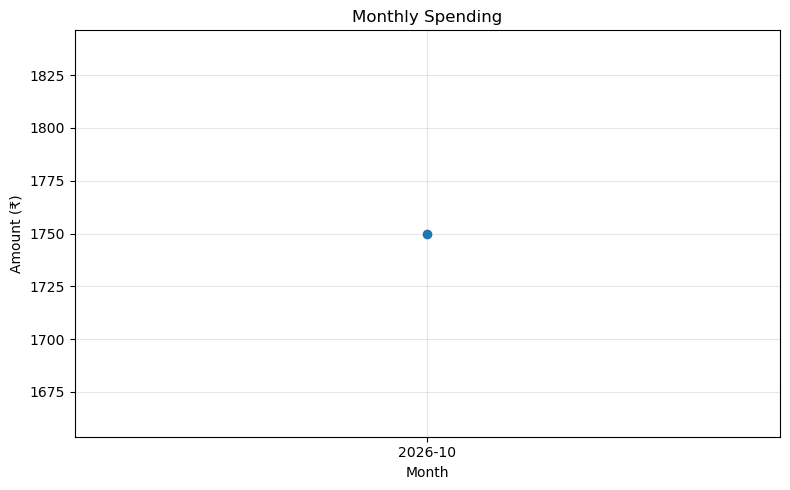

In [64]:
def spending_by_month(data=None):
    data = expenses if data is None else data
    totals = defaultdict(float)

    for item in data:
        month = item["date"][:7]  # YYYY-MM
        totals[month] += item["amount"]

    return {month: round(amount, 2) for month, amount in sorted(totals.items())}


def plot_monthly_spending(data=None):
    monthly = spending_by_month(data)
    if not monthly:
        print("No monthly data available.")
        return

    plt.figure(figsize=(8, 5))
    plt.plot(list(monthly.keys()), list(monthly.values()), marker="o")
    plt.title("Monthly Spending")
    plt.xlabel("Month")
    plt.ylabel("Amount (₹)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


print("Monthly totals:")
for month, amount in spending_by_month().items():
    print(f"{month}: ₹{amount:,.2f}")

plot_monthly_spending()

## 10. Weekly Spending Analysis

In [65]:
def spending_by_week(data=None):
    data = expenses if data is None else data

    totals = defaultdict(float)

    for item in data:
        date = datetime.strptime(item["date"], "%Y-%m-%d")
        year, week, _ = date.isocalendar()

        week_key = f"{year}-W{week:02d}"
        totals[week_key] += item["amount"]

    return {
        week: round(amount, 2)
        for week, amount in sorted(totals.items())
    }

In [66]:
# Display weekly spending
def show_weekly_spending(data=None):
    weekly = spending_by_week(data)

    if not weekly:
        print("No weekly data available.")
        return

    print("Weekly Spending:")
    for week, amount in weekly.items():
        print(f"{week}: ₹{amount:,.2f}")

In [67]:
show_weekly_spending()


Weekly Spending:
2026-W40: ₹1,750.00


In [68]:
def plot_weekly_spending(data=None):
    weekly = spending_by_week(data)

    if not weekly:
        print("No weekly data available for the chart.")
        return

    plt.figure(figsize=(8, 5))
    plt.bar(weekly.keys(), weekly.values())

    plt.title("Weekly Spending")
    plt.xlabel("Week")
    plt.ylabel("Amount (₹)")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

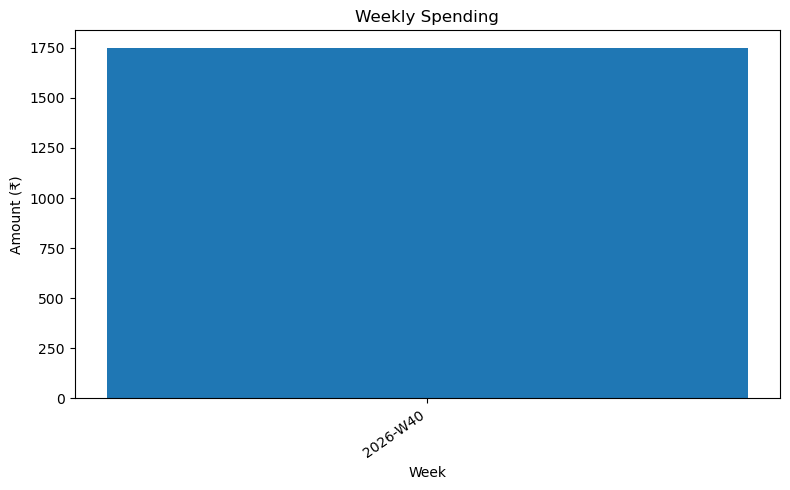

In [69]:
plot_weekly_spending()

## 11. Search and Filter Expenses

A small search feature makes the tracker more practical. Users can filter by category or search for a word in the description.

In [70]:
def filter_expenses(category=None, keyword=None, data=None):
    data = expenses if data is None else data
    results = data

    if category:
        results = [
            item for item in results
            if item["category"].lower() == category.lower()
        ]

    if keyword:
        keyword = keyword.lower()
        results = [
            item for item in results
            if keyword in item["description"].lower()
        ]

    return results


print("Food expenses:")
view_expenses(filter_expenses(category="Food"))

Food expenses:
#   Date         Category          Description                  Amount
----------------------------------------------------------------------
1   2026-10-01   Food              Lunch                    ₹   120.00
2   2026-10-03   Food              Dinner                   ₹   150.00


## 12. Interactive Menu

The original project specification describes a menu-driven command-line application. The function below brings that idea into the Jupyter notebook. Run `run_tracker()` when you want to use the interactive version.

**Menu:**
1. Add an Expense
2. View All Expenses
3. Generate Report
4. Show Charts
5. Save and Exit

In [71]:
def run_tracker():
    """Run the interactive command-line style tracker inside Jupyter."""
    while True:
        print("\n" + "=" * 40)
        print("WELCOME TO PERSONAL EXPENSE TRACKER")
        print("=" * 40)
        print("1. Add an Expense")
        print("2. View All Expenses")
        print("3. Generate Report")
        print("4. Show Charts")
        print("5. Save and Exit")

        choice = input("Enter your choice: ").strip()

        if choice == "1":
            try:
                amount = input("Enter amount: ")
                category = input("Enter category: ")
                description = input("Enter description: ")
                date = input("Enter date (YYYY-MM-DD) or press Enter for today: ").strip()
                date = date or None

                item = add_expense(amount, category, description, date)
                print(f"Expense added successfully: {item}")
            except ValueError as error:
                print(f"Invalid input: {error}")

        elif choice == "2":
            view_expenses()

        elif choice == "3":
            generate_report()

        elif choice == "4":
            plot_category_bar()
            plot_category_pie()

        elif choice == "5":
            save_expenses()
            print("Thank you for using Personal Expense Tracker!")
            break

        else:
            print("Please enter a number from 1 to 5.")


## 13. Error Handling Demonstration

The project should not crash when a user enters invalid data. The examples below show how the validation catches common mistakes.

In [72]:
test_inputs = ["abc", "-50", "0"]

for value in test_inputs:
    try:
        validate_amount(value)
    except ValueError as error:
        print(f"Input {value!r} -> handled safely: {error}")

try:
    validate_date("02-10-2026")
except ValueError as error:
    print(f"Invalid date -> handled safely: {error}")

Input 'abc' -> handled safely: Please enter a valid number.
Input '-50' -> handled safely: Amount should be greater than zero.
Input '0' -> handled safely: Amount should be greater than zero.
Invalid date -> handled safely: Please enter date in YYYY-MM-DD format.


# 14. Conclusion

Conclusion
The project starts as a simple expense logger and can gradually grow into a complete personal finance application. The code is separated into small functions so that a beginner can understand, test, and improve each part independently.